# K-Means cluster
### K-Means is an unsupervised machine learning algorithm that groups similar data points into K clusters by minimizing the distance between each data point and the centroid (mean) of its assigned cluster.

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

In [67]:
iris = load_iris()

In [68]:
#create a dataframe

x = pd.DataFrame(
    x,
    columns = iris.feature_names
)
print(x.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.900681          1.019004          -1.340227         -1.315444
1          -1.143017         -0.131979          -1.340227         -1.315444
2          -1.385353          0.328414          -1.397064         -1.315444
3          -1.506521          0.098217          -1.283389         -1.315444
4          -1.021849          1.249201          -1.340227         -1.315444


### Feature Scaling

In [69]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

### Plot the Dataset

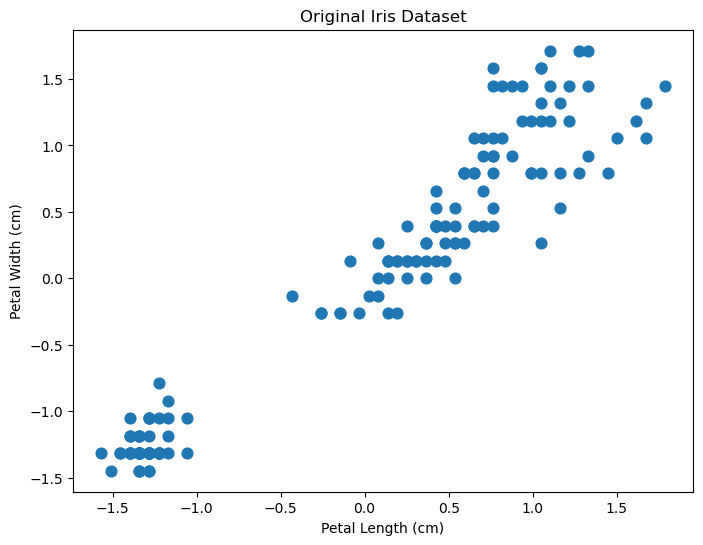

In [70]:
### plot the dataset
plt.figure(figsize=(8,6))

plt.scatter(
    x["petal length (cm)"],
    x["petal width (cm)"],
    s=60
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Original Iris Dataset")

plt.show()

### Model Creation and Training

In [89]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

In [92]:
clusters = kmeans.fit_predict(x_scaled)

D:\Softwares\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [93]:
print(kmeans.n_clusters)

3


In [94]:
# Add a new column called "Cluster"
x["Cluster"] = clusters

# View first few rows
print(x.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0          -0.900681          1.019004          -1.340227         -1.315444   
1          -1.143017         -0.131979          -1.340227         -1.315444   
2          -1.385353          0.328414          -1.397064         -1.315444   
3          -1.506521          0.098217          -1.283389         -1.315444   
4          -1.021849          1.249201          -1.340227         -1.315444   

   Cluster  
0        1  
1        2  
2        2  
3        2  
4        1  


In [95]:
# Add a new column called "Cluster"
x["Cluster"] = clusters

# View first few rows
print(x.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0          -0.900681          1.019004          -1.340227         -1.315444   
1          -1.143017         -0.131979          -1.340227         -1.315444   
2          -1.385353          0.328414          -1.397064         -1.315444   
3          -1.506521          0.098217          -1.283389         -1.315444   
4          -1.021849          1.249201          -1.340227         -1.315444   

   Cluster  
0        1  
1        2  
2        2  
3        2  
4        1  


In [96]:
# Print centroid coordinates
print(kmeans.cluster_centers_)

[[ 0.57100359 -0.37176778  0.69111943  0.66315198]
 [-0.81623084  1.31895771 -1.28683379 -1.2197118 ]
 [-1.32765367 -0.373138   -1.13723572 -1.11486192]]


In [97]:
# Print the WCSS (Inertia)
print("Inertia:", kmeans.inertia_)

Inertia: 191.02473685317983


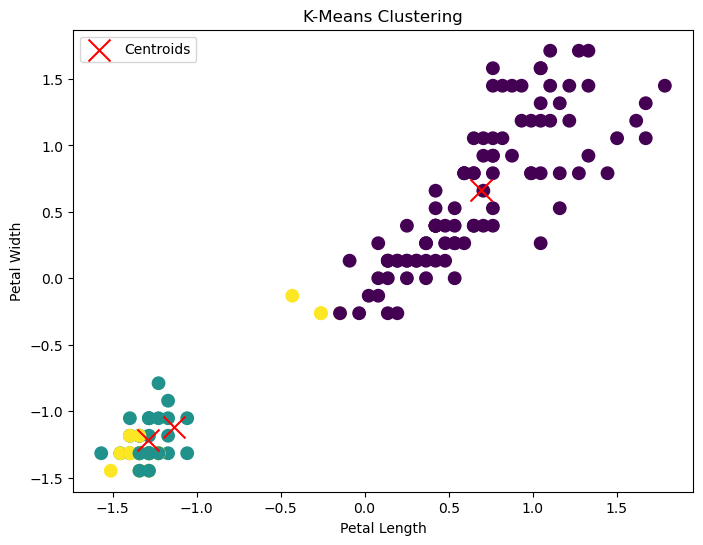

In [98]:
# Plot clustered data
plt.figure(figsize=(8,6))

plt.scatter(
    x["petal length (cm)"],
    x["petal width (cm)"],
    c=clusters,
    cmap="viridis",
    s=80
)

# Plot centroids
plt.scatter(
    kmeans.cluster_centers_[:,2],
    kmeans.cluster_centers_[:,3],
    c="red",
    marker="x",
    s=250,
    label="Centroids"
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("K-Means Clustering")
plt.legend()

plt.show()

In [99]:
# Store WCSS values
wcss = []

# Try K from 1 to 10
for k in range(1,11):

    # Create model
    temp_model = KMeans(n_clusters=k, random_state=42)

    # Train model
    temp_model.fit(x_scaled)

    # Store inertia (WCSS)
    wcss.append(temp_model.inertia_)

D:\Softwares\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Softwares\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Softwares\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Softwares\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with M

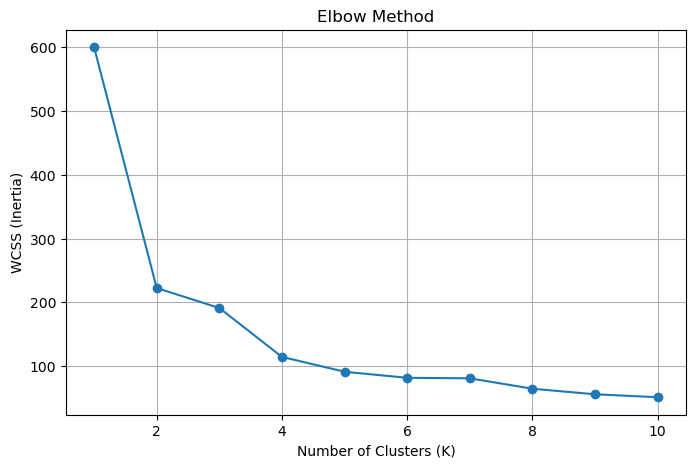

In [100]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1,11),
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")

plt.grid(True)

plt.show()

In [101]:
print(kmeans.n_clusters)
print(len(kmeans.cluster_centers_))

3
3
